# Semantic and Keyword-Based Tool Retrieval with RRF and LLM Reranking

**Technologies:** LangGraph, Gemini, Qdrant, Sentence-Transformers, BM25, and MCP.

## What this notebook does

- It uses hybrid search to find relevant MCP tools by combining semantic vector search and BM25 keyword search.
- It combines both rankings with Reciprocal Rank Fusion (RRF).
- It uses Gemini to rerank results and pick the best matches.
- It can fetch more tools when the agent needs them during execution.
- It uses RAG to search PDF, TXT, and Markdown files.
- It searches the tool catalog, request history, and loaded documents.
- It uses LangGraph to manage tool selection, execution, and the workflow.
- It tests the agent with different requests and shows the execution flow.

## Notebook sections

1. Setup and configuration
2. Design decisions
3. Why Qdrant
4. Tool index, knowledge base, and system tools
5. MCP connection and tool indexing
6. Retrieval evaluation
7. LangGraph agent
8. Workflow visualization
9. Demo scenarios
10. Interactive chat
11. Limitations and future improvements

**Before running:** Set `GEMINI_API_KEY` and `POSTMAN_API_KEY` in the `.env` file, configure `DOC_PATHS`, and make sure Node.js is installed.

## 1. Setup and configuration

Set the options in the next cell. Add the PDF, TXT, or Markdown file paths or URLs to `DOC_PATHS`.

In [1]:
import asyncio
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import uuid
from collections import Counter
from pathlib import Path
from typing import Annotated, Literal, TypedDict

import requests
from dotenv import load_dotenv
from IPython.display import Image, Markdown, display
from langchain_core.messages import (
    AIMessage, HumanMessage, SystemMessage, ToolMessage, trim_messages,
)
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from pypdf import PdfReader
from qdrant_client import QdrantClient, models

# Load configuration
load_dotenv()
CONFIG_PATH = Path.cwd() / "config.json"

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

# ---------------- Knowledge base documents  ----------------
# Local paths or URLs. Supported: .pdf  .txt  .md
DOC_PATHS: list[str] = [
    "https://www.paypalobjects.com/webstatic/en_IT/developer/docs/pdf/paypalpro.pdf",
    #  other docs can be added here, for example:
    # "docs/notes.txt",
    # "docs/other_doc.pdf",
]


# ---------------- Models ----------------
GROQ_MODEL = CONFIG["models"]["groq_model"]
EMBED_MODEL = CONFIG["models"]["embed_model"]

# ---------------- Vector store ----------------
QDRANT_PATH = CONFIG["vector_store"]["qdrant_path"]
TOOLS_COLLECTION = CONFIG["vector_store"]["tools_collection"]
KB_COLLECTION = CONFIG["vector_store"]["kb_collection"]

# ---------------- Retrieval / agent limits ----------------
RETRIEVE_K = CONFIG["retrieval_agent_limits"]["retrieve_k"]
SELECT_N = CONFIG["retrieval_agent_limits"]["select_n"]
MAX_ACTIVE = CONFIG["retrieval_agent_limits"]["max_active"]
KB_TOP_K = CONFIG["retrieval_agent_limits"]["kb_top_k"]

CHUNK_SIZE = CONFIG["retrieval_agent_limits"]["chunk_size"]
CHUNK_OVERLAP = CONFIG["retrieval_agent_limits"]["chunk_overlap"]

MAX_HISTORY_MESSAGES = CONFIG["retrieval_agent_limits"]["max_history_messages"]
MAX_TOOL_CHARS = CONFIG["retrieval_agent_limits"]["max_tool_chars"]
TOOL_RETRIES = CONFIG["retrieval_agent_limits"]["tool_retries"]

CONFIRM_DESTRUCTIVE = CONFIG["retrieval_agent_limits"]["confirm_destructive"]


# ---------------- MCP servers (add more entries to add more servers) ----------------
MCP_CONFIG = {
    "postman": {
        "transport": "stdio",
        "command": shutil.which("npx") or ("npx.cmd" if os.name == "nt" else "npx"),
        "args": ["-y", "@postman/postman-mcp-server", "--full"],
        "env": {
            "POSTMAN_API_KEY": os.getenv("POSTMAN_API_KEY"),
            "PATH": os.getenv("PATH", ""),
        },
    }
}

print("Config OK \n LLM:", GROQ_MODEL, "\n embeddings:", EMBED_MODEL, "\n Qdrant: local", QDRANT_PATH)

Config OK 
 LLM: openai/gpt-oss-120b 
 embeddings: all-MiniLM-L6-v2 
 Qdrant: local qdrant_data


## 2. Design decisions

### 2.1 Agent structure

This notebook uses LangGraph to manage tool selection and execution.

```text
select_tools -> agent <-> tools
                  -> request_more_tools -> agent
```

- The LLM gets three meta tools and only the top-N service tools selected for the request.
- `knowledge_base_search` searches documents with RAG.
- `system_search` looks through the tool catalog, request history, and loaded documents.
- `request_more_tools` finds more tools when needed.
- Tool retrieval, reranking, retries, and logging are handled in code.

### 2.2 Tool selection and routing

Tool selection happens in two steps:

1. **Hybrid retrieval:** Semantic search with Qdrant and keyword search with BM25 find relevant tools. RRF combines the results, and Gemini reranks them.
2. **Intent routing:** The LLM decides whether to use document search, system search, or service tools for the request.

If more tools are needed, the agent calls `request_more_tools` to fetch them.

### 2.3 State management

- LangGraph keeps track of messages, selected tools, and request IDs.
- `MemorySaver` keeps the conversation state across turns with a thread ID.
- Conversation history and tool output are limited so the context stays manageable.
- `RunLog` stores requests, tool calls, status, and execution time. `system_search` can use these logs to answer earlier requests.

### 2.4 Scalability

- Only the selected tools are passed to the LLM so the context stays manageable as the catalog grows.
- Tool hashes help detect changes so only new or updated tools are re-indexed.
- More MCP servers can be added through `MCP_CONFIG`.
- Document chunks are tracked by content so unchanged content is not re-indexed.
- Qdrant can run locally or as a server.
- BM25 runs in memory right now, which may become an issue with very large document collections.

### 2.5 Error handling

| Problem | How it's handled |
|---|---|
| Temporary connection errors | Retried with exponential backoff |
| Invalid tool arguments | Returned to the LLM so it can fix the call |
| Unknown tool | The agent can fetch more tools |
| Reranking failure | Falls back to hybrid search results |
| LLM failure | Retries once, then returns an error |
| Large tool output | Truncated |
| Destructive action | Requires human confirmation |
| Document loading failure | Skips the document and reports the error |
| Too many graph steps | Limited by the recursion limit |

## 3. Why Qdrant (and not FAISS or others)

**Short version:** Qdrant fits this project well because the data includes metadata like type and source document, and it changes over time. Qdrant treats both as first-class features. FAISS is mainly a fast math library, not a database.

**HNSW (internal graph indexing).** Qdrant builds a layered proximity graph over the vectors. Each vector links to nearby vectors. Search starts on a sparse top layer, moves toward the query, and then drops to denser layers. This gives roughly logarithmic search time instead of scanning every vector.

**Single-pass filtered traversal.** If only one document is needed, there are two naive options:

- Post-filter: take the top-k results first, then filter. This often returns too few or zero matches.
- Pre-filter: filter first, then do a brute-force search. This is slow on large sets.

Qdrant applies the payload filter while walking the graph. It adds extra graph links for indexed payload fields so filtered regions stay connected. This is a single pass with full recall.

| | Qdrant | FAISS | pgvector |
|---|---|---|---|
| HNSW index | Yes | Yes | Yes |
| Metadata filter inside the graph walk | Yes | Not built in; you manage ID selectors or post-filter | Filter applied through SQL planning; selective filters can under-return |
| Persistence and upsert/delete by id | Built in | You build it | Built in (Postgres) |
| Payload stored with vector | Yes | No | Yes |
| Embedded dev mode → server → cluster, same API | Yes | n/a (library) | Needs Postgres |

**Honest trade-offs**

- For only a few hundred tools, FAISS or plain NumPy would also work.
- The deciding factors are the growing document corpus, filters, and incremental updates.
- The embedded local mode used here is for development and uses brute-force search. HNSW and filtered traversal apply when `QDRANT_URL` points to a Qdrant server. The code stays the same.

## 4. Building blocks

### 4.0 Shared helpers

This notebook uses a tokenizer, BM25, reciprocal rank fusion, and a few text utilities. BM25 is written out here to keep the dependency list small and the ranking easy to follow.

In [2]:
def tokenize(text: str) -> list[str]:
    """Lowercase words; splits camelCase / snake_case / punctuation."""
    text = re.sub(r"([a-z0-9])([A-Z])", r"\1 \2", text or "")
    return re.findall(r"[a-z0-9]+", text.lower())


def text_of(message) -> str:
    """Flatten message content (str or list of blocks) to plain text."""
    content = message.content
    if isinstance(content, str):
        return content
    parts = []
    for block in content:
        if isinstance(block, str):
            parts.append(block)
        elif isinstance(block, dict) and block.get("type") == "text":
            parts.append(block.get("text", ""))
    return "".join(parts)


def rrf(rankings: list[list[str]], k: int = 60) -> list[str]:
    """Reciprocal Rank Fusion: score = sum(1 / (k + rank)) across ranked lists."""
    scores: dict[str, float] = {}
    for ranking in rankings:
        for rank, key in enumerate(ranking, start=1):
            scores[key] = scores.get(key, 0.0) + 1.0 / (k + rank)
    return [key for key, _ in sorted(scores.items(), key=lambda x: x[1], reverse=True)]


class BM25:
    """Small in-memory BM25 over {doc_id: text}."""

    def __init__(self, docs: dict[str, str], k1: float = 1.5, b: float = 0.75):
        self.ids = list(docs)
        self.k1, self.b = k1, b
        self.tf = [Counter(tokenize(docs[i])) for i in self.ids]
        self.len = [sum(c.values()) for c in self.tf]
        self.avg = sum(self.len) / max(len(self.len), 1)
        self.df = Counter(tok for c in self.tf for tok in c)

    def search(self, query: str, k: int, allowed: set[str] | None = None) -> list[str]:
        q, n = tokenize(query), len(self.ids)
        scored = []
        for i, doc_id in enumerate(self.ids):
            if allowed is not None and doc_id not in allowed:
                continue
            score = 0.0
            for tok in q:
                f = self.tf[i].get(tok)
                if not f:
                    continue
                idf = math.log(1 + (n - self.df[tok] + 0.5) / (self.df[tok] + 0.5))
                score += idf * f * (self.k1 + 1) / (
                    f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg)
                )
            if score > 0:
                scored.append((score, doc_id))
        scored.sort(reverse=True)
        return [d for _, d in scored[:k]]


def ensure_collection(client: QdrantClient, name: str, dim: int):
    """Create the collection; recreate if the embedding dimension changed."""
    if client.collection_exists(name):
        if client.get_collection(name).config.params.vectors.size == dim:
            return
        client.delete_collection(name)
    client.create_collection(
        name, vectors_config=models.VectorParams(size=dim, distance=models.Distance.COSINE)
    )


def scroll_all(client: QdrantClient, name: str, fields: list[str]):
    """Yield every point (id + selected payload fields) in a collection."""
    offset = None
    while True:
        points, offset = client.scroll(
            name, limit=256, offset=offset, with_payload=fields, with_vectors=False
        )
        yield from points
        if offset is None:
            break

### 4.1 Tool index (dynamic discovery, incremental sync, hybrid search)

The metadata comes from whatever the MCP servers expose: name, description, input schema, and parameter descriptions. A SHA-256 content hash, including the embedding model name, shows whether a tool is new, changed, unchanged, or removed.

In [3]:
def tool_to_record(t) -> dict:
    """Pull name, description and input schema off an MCP / LangChain tool."""
    schema = t.args_schema if isinstance(t.args_schema, dict) else {}
    props = schema.get("properties", {}) or {}
    return {
        "name": t.name,
        "description": t.description or "",
        "schema": schema,
        "params": {k: (v.get("description", "") if isinstance(v, dict) else "")
                   for k, v in props.items()},
    }


def tool_embedding_text(rec: dict) -> str:
    params = "; ".join(f"{k} {d[:100]}".strip() for k, d in rec["params"].items())
    return f"{' '.join(tokenize(rec['name']))}. {rec['description']}\nParameters: {params}"


def tool_hash(rec: dict, model: str) -> str:
    blob = json.dumps({"n": rec["name"], "d": rec["description"], "s": rec["schema"], "m": model},
                      sort_keys=True, default=str)
    return hashlib.sha256(blob.encode()).hexdigest()


def stable_id(*parts: str) -> str:
    return str(uuid.uuid5(uuid.NAMESPACE_URL, "|".join(parts)))


class ToolIndex:
    def __init__(self, client: QdrantClient, embedder, collection: str = TOOLS_COLLECTION):
        self.client, self.embedder, self.collection = client, embedder, collection
        self.records: dict[str, dict] = {}
        self.bm25: BM25 | None = None

    def _embed(self, texts: list[str]) -> list[list[float]]:
        vecs = self.embedder.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        return [list(map(float, v)) for v in vecs]

    def sync(self, tools) -> dict:
        """Bring Qdrant in line with the tools the servers expose right now."""
        records = {}
        for t in tools:
            rec = tool_to_record(t)
            rec["hash"] = tool_hash(rec, EMBED_MODEL)
            records[rec["name"]] = rec

        ensure_collection(self.client, self.collection, len(self._embed(["probe"])[0]))
        existing = {p.payload["name"]: (p.id, p.payload["hash"])
                    for p in scroll_all(self.client, self.collection, ["name", "hash"])}

        new = [n for n in records if n not in existing]
        changed = [n for n in records if n in existing and existing[n][1] != records[n]["hash"]]
        removed = [n for n in existing if n not in records]

        todo = new + changed
        for i in range(0, len(todo), 64):
            batch = todo[i:i + 64]
            vectors = self._embed([tool_embedding_text(records[n]) for n in batch])
            self.client.upsert(self.collection, points=[
                models.PointStruct(
                    id=stable_id("mcp-tool", n), vector=v,
                    payload={"name": n, "description": records[n]["description"],
                             "hash": records[n]["hash"]})
                for n, v in zip(batch, vectors)])
        if removed:
            self.client.delete(self.collection, points_selector=models.PointIdsList(
                points=[existing[n][0] for n in removed]))

        self.records = records
        self.bm25 = BM25({n: f"{n} {n} {n} {r['description']} {' '.join(r['params'])}"
                          for n, r in records.items()})
        return {"total": len(records), "new": len(new), "modified": len(changed),
                "removed": len(removed), "unchanged": len(records) - len(new) - len(changed)}

    def search(self, query: str, top_k: int = RETRIEVE_K, fetch_k: int = 40,
               mode: Literal["hybrid", "semantic", "keyword"] = "hybrid") -> list[dict]:
        semantic, keyword = [], []
        if mode in ("hybrid", "semantic"):
            hits = self.client.query_points(self.collection, query=self._embed([query])[0],
                                            limit=fetch_k, with_payload=["name"]).points
            semantic = [h.payload["name"] for h in hits if h.payload["name"] in self.records]
        if mode in ("hybrid", "keyword") and self.bm25:
            keyword = self.bm25.search(query, fetch_k)
        ranked = rrf([r for r in (semantic, keyword) if r])
        return [self.records[n] for n in ranked[:top_k]]

### 4.2 Knowledge base for the RAG tool (pdf / txt / md)

The pipeline is simple: load → chunk → embed → upsert into Qdrant, then run hybrid retrieval with dense + BM25 + RRF and an optional `source` filter. That is the filtered-traversal feature from section 3.

- PDFs are chunked page by page so each passage keeps its page number for citations.
- Chunk IDs are built from source + page + text hash. Unchanged chunks are skipped, and edited or removed content is replaced or deleted.
- If a document fails to load, it is skipped and reported. Its stored chunks are not deleted.

In [4]:
class KnowledgeBase:
    SUPPORTED = {".pdf", ".txt", ".md"}

    def __init__(self, client, embedder, collection=KB_COLLECTION, cache_dir=".kb_cache"):
        self.client, self.embedder, self.collection = client, embedder, collection
        self.cache = Path(cache_dir)
        self.splitter = RecursiveCharacterTextSplitter(
            chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP,
            separators=["\n\n", "\n", ". ", " ", ""])
        self.chunks: dict[str, dict] = {}
        self.bm25: BM25 | None = None

    def _embed(self, texts):
        vecs = self.embedder.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        return [list(map(float, v)) for v in vecs]

    def _local_path(self, ref: str) -> Path:
        """Return a local file for a path or URL (URLs are cached on disk)."""
        if not ref.startswith(("http://", "https://")):
            return Path(ref)
        self.cache.mkdir(exist_ok=True)
        suffix = Path(ref.split("?")[0]).suffix.lower() or ".txt"
        target = self.cache / f"{hashlib.sha1(ref.encode()).hexdigest()}{suffix}"
        if not target.exists():
            resp = requests.get(ref, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
            resp.raise_for_status()
            target.write_bytes(resp.content)
        return target

    def _read(self, ref: str) -> list[tuple[int | None, str]]:
        path = self._local_path(ref)
        ext = path.suffix.lower()
        if ext not in self.SUPPORTED:
            raise ValueError(f"unsupported file type '{ext}' (use {sorted(self.SUPPORTED)})")
        if ext == ".pdf":
            return [(i + 1, page.extract_text() or "")
                    for i, page in enumerate(PdfReader(str(path)).pages)]
        return [(None, path.read_text(encoding="utf-8", errors="replace"))]

    def sync(self, refs: list[str]) -> dict:
        desired, failed = {}, {}
        for ref in refs:
            try:
                for page, text in self._read(ref):
                    for piece in self.splitter.split_text(text):
                        piece = piece.strip()
                        if len(piece) < 40:
                            continue
                        cid = stable_id("kb", ref, str(page), hashlib.sha1(piece.encode()).hexdigest())
                        desired[cid] = {"id": cid, "text": piece, "source": ref, "page": page}
            except Exception as e:  # one bad document must not break the rest
                failed[ref] = f"{type(e).__name__}: {e}"

        ensure_collection(self.client, self.collection, len(self._embed(["probe"])[0]))
        existing = {p.id: p.payload.get("source") for p in scroll_all(self.client, self.collection, ["source"])}

        new = [c for c in desired if c not in existing]
        stale = [c for c, src in existing.items() if c not in desired and src not in failed]

        for i in range(0, len(new), 64):
            batch = [desired[c] for c in new[i:i + 64]]
            vectors = self._embed([c["text"] for c in batch])
            self.client.upsert(self.collection, points=[
                models.PointStruct(id=c["id"], vector=v,
                                   payload={k: c[k] for k in ("text", "source", "page")})
                for c, v in zip(batch, vectors)])
        if stale:
            self.client.delete(self.collection, points_selector=models.PointIdsList(points=stale))
            
        self.chunks = desired
        self.bm25 = BM25({c: d["text"] for c, d in desired.items()}) if desired else None
        return {"documents": len(refs) - len(failed), "chunks": len(desired), "new": len(new),
                "removed": len(stale), "unchanged": len(desired) - len(new), "failed": failed}

    def sources(self) -> dict[str, int]:
        return dict(Counter(c["source"] for c in self.chunks.values()))

    def search(self, query: str, top_k: int = KB_TOP_K, source: str | None = None,
               fetch_k: int = 30, mode: str = "hybrid") -> list[dict]:
        if not self.chunks:
            return []
        flt = (models.Filter(must=[models.FieldCondition(
            key="source", match=models.MatchValue(value=source))]) if source else None)
        semantic, keyword = [], []
        if mode in ("hybrid", "semantic"):
            hits = self.client.query_points(self.collection, query=self._embed([query])[0],
                                            limit=fetch_k, query_filter=flt, with_payload=False).points
            semantic = [str(h.id) for h in hits if str(h.id) in self.chunks]
        if mode in ("hybrid", "keyword") and self.bm25:
            allowed = {c for c, d in self.chunks.items() if d["source"] == source} if source else None
            keyword = self.bm25.search(query, fetch_k, allowed)
        return [self.chunks[c] for c in rrf([r for r in (semantic, keyword) if r])[:top_k]]

### 4.3 System state: run log and the two required tools

**`RunLog`** records each user request, which tools were selected, each tool call, its status, and its latency.

**`knowledge_base_search`** is the RAG tool. It answers questions from documents and returns passages with source and page for citation.

**`system_search`** is the system search tool. It queries the system itself, with a `scope` chosen by the LLM:

- `tools`: hybrid search across the full tool catalog, not just the currently bound tools
- `requests`: recent requests, tool calls, and statuses
- `knowledge`: which documents are loaded

Both tools are created through a factory so they share the same index, knowledge base, and log as the graph. The tool names are not hard-coded; the catalog comes from live discovery.

In [5]:
class RunLog:
    """In-memory audit trail of requests and tool calls (swap for a DB / OpenTelemetry in prod)."""

    def __init__(self):
        self.requests: list[dict] = []

    def start(self, text: str, selected: list[str]) -> int:
        self.requests.append({"id": len(self.requests) + 1, "text": text[:200],
                              "time": time.strftime("%H:%M:%S"), "selected": selected, "calls": []})
        return len(self.requests)

    def call(self, rid: int, tool: str, args: dict, status: str, ms: float, error: str = ""):
        self.requests[rid - 1]["calls"].append({
            "tool": tool, "args": json.dumps(args, default=str)[:150],
            "status": status, "ms": round(ms), "error": error[:200]})

    def recent(self, n: int = 5) -> str:
        if not self.requests:
            return "No requests have been logged yet."
        lines = []
        for r in reversed(self.requests[-n:]):
            calls = r["calls"]
            bad = [c for c in calls if c["status"] != "success"]
            status = ("no tools called" if not calls else
                      "all calls succeeded" if not bad else f"{len(bad)} of {len(calls)} calls failed")
            tag = "  <- current request (the one asking)" if r is self.requests[-1] else ""
            lines.append(f"Request #{r['id']} at {r['time']}: \"{r['text']}\"{tag}\n  result: {status}")
            for c in calls:
                err = f" error={c['error']}" if c["error"] else ""
                lines.append(f"  - {c['tool']}({c['args']}) -> {c['status']} in {c['ms']} ms{err}")
        return "\n".join(lines)


def make_meta_tools(index: ToolIndex, kb: KnowledgeBase, run_log: RunLog) -> list:
    @tool
    def knowledge_base_search(query: str, source: str = "") -> str:
        """Search the ingested documentation / guides (RAG) and return the most relevant
        passages with source and page. Use for questions about concepts, how-tos, product
        behaviour or anything that should be answered from documents. Answer ONLY from
        the returned passages and cite source and page.
        query: the information needed, phrased as a search query.
        source: optional exact document path/URL to restrict the search ('' = all documents)."""
        hits = kb.search(query, top_k=KB_TOP_K, source=source or None)
        if not hits:
            return "No relevant passages found (the knowledge base may be empty or the source filter wrong)."
        return "\n\n".join(
            f"[{i}] source={h['source']} page={h['page'] or 'n/a'}\n{h['text']}"
            for i, h in enumerate(hits, 1))

    @tool
    def system_search(query: str, scope: Literal["tools", "requests", "knowledge"] = "tools") -> str:
        """Search the assistant system itself, not the user's data.
        scope='tools': find tools/capabilities that exist in the full catalog (e.g. what can
          manage X). scope='requests': show recent requests, the tools called and their status
          (e.g. status of my last request, what failed). scope='knowledge': list loaded documents.
        query: what to look for (ignored for scope='requests' and 'knowledge')."""
        if scope == "requests":
            return run_log.recent()
        if scope == "knowledge":
            src = kb.sources()
            return "\n".join(f"- {s} ({n} chunks)" for s, n in src.items()) or "No documents loaded."
        hits = index.search(query, top_k=8)
        if not hits:
            return "No matching tools found."
        return f"{len(index.records)} tools in catalog. Best matches:\n" + "\n".join(
            f"- {h['name']}: {h['description'][:160].replace(chr(10), ' ')}" for h in hits)

    return [knowledge_base_search, system_search]


@tool
def request_more_tools(query: str) -> str:
    """Ask for different service tools when none of the currently available tools can do
    what is needed. query: short description of the capability required."""
    return ""  # intercepted by the graph; never executed directly

## 5. Connect to MCP and build the indexes

### 5.1 Discover tools and sync the tool index

Nothing is hard-coded here. `get_tools()` returns whatever the server exposes right now.

In [6]:

import os
import shutil
from pathlib import Path
from contextlib import AsyncExitStack

from mcp import ClientSession
from mcp.client.stdio import stdio_client, StdioServerParameters
from langchain_mcp_adapters.tools import load_mcp_tools
from sentence_transformers import SentenceTransformer
from qdrant_client import QdrantClient

# 1. Close previous Qdrant client before reopening local storage
if "qdrant" in globals():
    try:
        qdrant.close()
    except Exception:
        pass

# 2. Load embedding model
embedder = SentenceTransformer(EMBED_MODEL)

# 3. Initialize Qdrant
qdrant = QdrantClient(path=QDRANT_PATH)

# 4. Find npx
npx_path = shutil.which("npx.cmd") or shutil.which("npx")

if not npx_path:
    raise FileNotFoundError("npx not found. Install Node.js.")

# 5. Close previous MCP connection if it exists
if "mcp_stack" in globals():
    try:
        await mcp_stack.aclose()
    except Exception:
        pass

if "mcp_log_file" in globals():
    try:
        mcp_log_file.close()
    except Exception:
        pass

# 6. Configure Postman MCP server
server_params = StdioServerParameters(
    command="cmd",
    args=[
        "/c",
        npx_path,
        "-y",
        "@postman/postman-mcp-server",
        "--full"
    ],
    env={
        **os.environ,
        "POSTMAN_API_KEY": os.getenv("POSTMAN_API_KEY")
    }
)

# 7. Connect using a real file for stderr
Path("./storage").mkdir(parents=True, exist_ok=True)

mcp_log_file = open(
    "./storage/mcp_server.log",
    "w",
    encoding="utf-8"
)

mcp_stack = AsyncExitStack()
await mcp_stack.__aenter__()

read_stream, write_stream = await mcp_stack.enter_async_context(
    stdio_client(server_params, errlog=mcp_log_file)
)

session = await mcp_stack.enter_async_context(
    ClientSession(read_stream, write_stream)
)

await session.initialize()

# 8. Discover MCP tools
all_tools = await load_mcp_tools(session)

print(f"MCP tools discovered: {len(all_tools)}")

# 9. Synchronize tools with Qdrant
tool_index = ToolIndex(qdrant, embedder)

sync_result = tool_index.sync(all_tools)

print("Tool index sync:", sync_result)


d:\dynamic_mcp_agent\mcp-agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6629.94it/s]


MCP tools discovered: 234
Tool index sync: {'total': 234, 'new': 234, 'modified': 0, 'removed': 0, 'unchanged': 0}


### 5.2 Ingest documents into the knowledge base

Run this cell again after editing `DOC_PATHS`. Only changed content is embedded.

In [7]:
kb = KnowledgeBase(qdrant, embedder)
stats = kb.sync(DOC_PATHS)
print({k: v for k, v in stats.items() if k != "failed"})
for ref, err in stats["failed"].items():
    print(f"  SKIPPED {ref}: {err}")

# Peek at retrieval, with and without the payload filter (filtered traversal, §3)
if kb.chunks:
    probe = "how are payments processed"
    print("\n--- unfiltered ---")
    for h in kb.search(probe, top_k=2):
        print(f"[page {h['page']}] {h['text'][:160].replace(chr(10), ' ')}...")
    print("\n--- filtered to one source ---")
    for h in kb.search(probe, top_k=2, source=DOC_PATHS[0]):
        print(f"[page {h['page']}] {h['text'][:160].replace(chr(10), ' ')}...")

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/BGFAGN+Courier', '/Encoding': '/WinAnsiEncoding', '/FirstChar': 32, '/FontDescriptor': IndirectObject(684, 0, 2131814023120), '/LastChar': 148, '/Subtype': '/Type1', '/Type': '/Font', '/Widths': [600, 600, 600, 600, 0, 600, 600, 0, 600, 600, 0, 0, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 0, 600, 0, 600, 0, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 600, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 600, 0, 600]}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictiona

{'documents': 1, 'chunks': 225, 'new': 225, 'removed': 0, 'unchanged': 0}

--- unfiltered ---
[page 64] Order Processing Verifying Transaction Status and Authenticity 64 Validate Instant Paym ent Notification (IPN) IPN enables you to receive messages about transac...
[page 3] Chapter 1 Getting Started with PayP al Pro .  .  .  .  .  .  .  .  .  .  .  .  .  .  . 11 Overview .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  ....

--- filtered to one source ---
[page 64] Order Processing Verifying Transaction Status and Authenticity 64 Validate Instant Paym ent Notification (IPN) IPN enables you to receive messages about transac...
[page 3] Chapter 1 Getting Started with PayP al Pro .  .  .  .  .  .  .  .  .  .  .  .  .  .  . 11 Overview .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  ....


## 6. Retrieval quality check (no hand-written queries)

Why check this? The agent can only use tools that retrieval surfaces. This is measured automatically here:

- For a random sample of discovered tools, the query is the first sentence of the tool description with the tool-name words removed.
- It checks whether that tool appears in the top 5 results (Recall@5) and its average reciprocal rank (MRR).
- It compares semantic-only, keyword-only, and hybrid search.

**Caveat:** the query is built from text that is also indexed, so the numbers are optimistic. This is mainly to compare modes and catch regressions, not to claim real-world accuracy.

In [8]:
def synthetic_query(rec: dict) -> str:
    first = re.split(r"(?<=[.!?])\s", rec["description"].strip())[0][:200]
    name_words = set(tokenize(rec["name"]))
    return " ".join(w for w in first.split() if not set(tokenize(w)) <= name_words)

def evaluate(index: ToolIndex, mode: str, names: list[str], k: int = 5):
    hit, rr = 0, 0.0
    for n in names:
        q = synthetic_query(index.records[n])
        ranked = [r["name"] for r in index.search(q, top_k=RETRIEVE_K, mode=mode)]
        if n in ranked[:k]:
            hit += 1
        if n in ranked:
            rr += 1 / (ranked.index(n) + 1)
    return hit / len(names), rr / len(names)

sample = random.Random(7).sample(list(tool_index.records), min(60, len(tool_index.records)))
print(f"{'mode':10s} Recall@5   MRR   (n={len(sample)})")
for mode in ("semantic", "keyword", "hybrid"):
    r5, mrr = evaluate(tool_index, mode, sample)
    print(f"{mode:10s} {r5:8.2f}  {mrr:5.2f}")

mode       Recall@5   MRR   (n=60)
semantic       0.77   0.63
keyword        0.92   0.84
hybrid         0.87   0.74


## 7. The LangGraph agent

These are the main responsibilities in the graph:

| Node | Type | Job |
|---|---|---|
| `select_tools` | code + LLM | hybrid search → RRF → LLM rerank; opens a `RunLog` entry |
| `agent` | LLM | tool-calling with only the selected tools plus the meta tools |
| `tools` | code | executes calls: retry, truncate, confirm destructive actions, log |
| `reselect` | code + LLM | handles `request_more_tools` and merges in the new tools |

In [9]:
SYSTEM_PROMPT = (
    "You are an operations assistant connected to external services through tools that are "
    "bound to you for this turn.\n"
    "Routing rules:\n"
    "1. Questions about documentation, guides, concepts or how something works: call "
    "knowledge_base_search and answer only from the returned passages, citing source and page. "
    "If nothing relevant comes back, say so.\n"
    "2. Questions about this assistant itself (what tools or capabilities exist, status or "
    "history of earlier requests, which documents are loaded): call system_search with the "
    "right scope.\n"
    "3. Tasks that read or change the user's account: use the bound service tools. If none "
    "fits, call request_more_tools with a short description of the capability needed.\n"
    "Prefer read-only tools. Create, update or delete only when the user clearly asks. "
    "If a request is vague, investigate with read-only tools before asking the user. "
    "Never invent results. If a tool returns an error, read it, fix your arguments or explain "
    "the problem plainly. Summarize results clearly."
)


def build_query(messages) -> str:
    """Latest user request plus a little recent context (helps follow-ups)."""
    last = max(i for i, m in enumerate(messages) if isinstance(m, HumanMessage))
    recent = [m for m in messages[max(0, last - 4):last] if text_of(m)]
    ctx = " | ".join(text_of(m)[:200] for m in recent)
    q = text_of(messages[last])
    return f"{q}\n(context: {ctx})" if ctx else q


def parse_ranked_names(text: str, valid: set[str]) -> list[str]:
    """Tool names from the reranker reply: JSON first, then names found in free text."""
    found: list[str] = []
    try:
        m = re.search(r"[\[{].*[\]}]", text, re.S)
        data = json.loads(m.group(0)) if m else None
        if isinstance(data, dict):
            data = next((v for v in data.values() if isinstance(v, list)), [])
        if isinstance(data, list):
            found = [str(x) for x in data if str(x) in valid]
    except Exception:
        pass
    if not found:
        pos = []
        for name in valid:
            m = re.search(rf"(?<![A-Za-z0-9_]){re.escape(name)}(?![A-Za-z0-9_])", text)
            if m:
                pos.append((m.start(), name))
        found = [n for _, n in sorted(pos)]
    return list(dict.fromkeys(found))


async def rerank(llm, query: str, candidates: list[dict], top_n: int) -> list[str]:
    """LLM reranking of hybrid-search candidates; falls back to hybrid order on any failure."""
    if not candidates:
        return []
    listing = "\n".join(f"- {c['name']}: {c['description'][:250].replace(chr(10), ' ')}"
                        for c in candidates)
    prompt = (
        f"A user made this request to an assistant that can call API tools:\n\"\"\"{query}\"\"\"\n\n"
        f"Candidate tools:\n{listing}\n\n"
        f"Pick the {top_n} tools most useful for the request, including prerequisite lookups "
        "(e.g. a tool to identify the current user, or a list/get tool to find an ID). Reply with "
        "ONLY a JSON array of exact tool names, best first. No other text.")
    chosen: list[str] = []
    try:
        chosen = parse_ranked_names(text_of(await llm.ainvoke(prompt)), {c["name"] for c in candidates})
    except Exception as e:
        print(f"[rerank failed, using hybrid order: {type(e).__name__}]")
    return (chosen or [c["name"] for c in candidates])[:top_n]


def clip(text: str, limit: int = MAX_TOOL_CHARS) -> str:
    return text if len(text) <= limit else (
        text[:limit] + f"\n...[truncated {len(text) - limit} chars; narrow the request or use filters]")


def to_text(result) -> str:
    if isinstance(result, str):
        return result
    try:
        return json.dumps(result, default=str, ensure_ascii=False)
    except Exception:
        return str(result)


def is_destructive(t) -> bool:
    """Read the MCP 'destructiveHint' annotation if the adapter exposes it."""
    ann = (getattr(t, "metadata", None) or {}).get("annotations")
    if ann is None:
        return False
    return bool(ann.get("destructiveHint") if isinstance(ann, dict) else getattr(ann, "destructiveHint", False))


TRANSIENT = (TimeoutError, ConnectionError, asyncio.TimeoutError, OSError)

In [10]:
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    selected: list[str]
    request_id: int


def build_graph(llm, index: ToolIndex, all_tools: list, run_log: RunLog, meta_tools: list):
    by_name = {t.name: t for t in all_tools}
    registry = {**by_name, **{t.name: t for t in meta_tools}}

    async def select_tools(state: AgentState):
        query = build_query(state["messages"])
        names = await rerank(llm, query, index.search(query, top_k=RETRIEVE_K), SELECT_N)
        rid = run_log.start(text_of(state["messages"][-1]), names)
        return {"selected": names, "request_id": rid}

    async def agent(state: AgentState):
        bound = [by_name[n] for n in state["selected"] if n in by_name]
        model = llm.bind_tools(bound + meta_tools + [request_more_tools])
        history = trim_messages(state["messages"], strategy="last", token_counter=len,
                                max_tokens=MAX_HISTORY_MESSAGES, start_on="human")
        last_error = None
        for attempt in range(2):                       # one retry for flaky tool-call generation
            try:
                response = await model.ainvoke([SystemMessage(content=SYSTEM_PROMPT)] + history)
                return {"messages": [response]}
            except Exception as e:
                last_error = e
                print(f"Model request failed: {type(e).__name__}: {e}")
                await asyncio.sleep(0.5)
                await asyncio.sleep(0.5)
        return {"messages": [AIMessage(
            content=f"I could not get a valid response from the model ({type(last_error).__name__}). "
                    "Please rephrase or try again.")]}

    async def reselect(state: AgentState):
        last: AIMessage = state["messages"][-1]
        selected, replies = list(state["selected"]), []
        for call in last.tool_calls:
            if call["name"] == "request_more_tools":
                query = call["args"].get("query", "")
                names = await rerank(llm, query, index.search(query, top_k=RETRIEVE_K), SELECT_N)
                selected = list(dict.fromkeys(names + selected))[:MAX_ACTIVE]
                content = f"Now available: {', '.join(names)}. Call them directly."
            else:
                content = "Not executed. Call it again now that the tools are updated."
            replies.append(ToolMessage(content=content, tool_call_id=call["id"], name=call["name"]))
        return {"messages": replies, "selected": selected}

    async def run_one(call: dict, rid: int) -> ToolMessage:
        name, args = call["name"], call.get("args", {})
        t0, status, error = time.perf_counter(), "success", ""
        t = registry.get(name)
        if t is None:
            content, status, error = f"Unknown tool '{name}'. Use request_more_tools to find it.", "error", "unknown tool"
        elif CONFIRM_DESTRUCTIVE and is_destructive(t) and (await asyncio.to_thread(
                input, f"\n[confirm] '{name}' is destructive. args={args}\nProceed? (y/N): "
        )).strip().lower() != "y":
            content, status, error = "The user declined this action.", "error", "declined"
        else:
            for attempt in range(TOOL_RETRIES):
                try:
                    content = clip(to_text(await t.ainvoke(args)))
                    break
                except TRANSIENT as e:                 # transient: back off and retry
                    if attempt == TOOL_RETRIES - 1:
                        content, status, error = f"Tool failed after retries: {e}", "error", str(e)
                    else:
                        await asyncio.sleep(0.5 * 2 ** attempt)
                except Exception as e:                 # semantic: let the LLM correct itself
                    content, status, error = f"Tool error ({type(e).__name__}): {e}", "error", str(e)
                    break
        run_log.call(rid, name, args, status, (time.perf_counter() - t0) * 1000, error)
        return ToolMessage(content=content, tool_call_id=call["id"], name=name, status=status)

    async def tools(state: AgentState):
        calls = state["messages"][-1].tool_calls
        return {"messages": list(await asyncio.gather(*(run_one(c, state["request_id"]) for c in calls)))}

    def route(state: AgentState):
        calls = getattr(state["messages"][-1], "tool_calls", None)
        if not calls:
            return END
        return "reselect" if any(c["name"] == "request_more_tools" for c in calls) else "tools"

    g = StateGraph(AgentState)
    g.add_node("select_tools", select_tools)
    g.add_node("agent", agent)
    g.add_node("reselect", reselect)
    g.add_node("tools", tools)
    g.add_edge(START, "select_tools")
    g.add_edge("select_tools", "agent")
    g.add_conditional_edges("agent", route, ["tools", "reselect", END])
    g.add_edge("tools", "agent")
    g.add_edge("reselect", "agent")
    return g.compile(checkpointer=MemorySaver())

In [11]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=os.getenv("GEMINI_API_KEY")
)
run_log = RunLog()
meta_tools = make_meta_tools(tool_index, kb, run_log)
graph = build_graph(llm, tool_index, all_tools, run_log, meta_tools)
print("Agent ready. Meta tools:", [t.name for t in meta_tools] + ["request_more_tools"])

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


Agent ready. Meta tools: ['knowledge_base_search', 'system_search', 'request_more_tools']


## 8. Graph visualization

The Mermaid web service is used to draw the graph. If the notebook is offline, the Mermaid source is printed instead so it can be pasted into any Mermaid viewer.

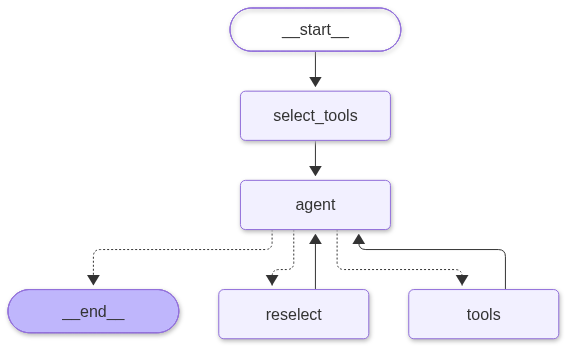

In [12]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"PNG rendering unavailable ({type(e).__name__}); Mermaid source:\n")
    print(graph.get_graph().draw_mermaid())

## 9. Demo scenarios

The `ask()` helper runs the graph step by step so the tool selection, routing, and execution can be seen. Each example follows a different path through the system:

1. **RAG tool:** answers from the loaded documents.
2. **System search (tools scope):** looks for tools across the full catalog.
3. **Service tool:** makes a real call to the MCP server.
4. **System search (requests scope):** checks the status of the previous request from `RunLog`.

All four use the same `thread_id`, so memory carries across turns.

In [13]:
THREAD = {"configurable": {"thread_id": "demo-1"}, "recursion_limit": 30}

async def ask(question: str, config: dict = THREAD, verbose: bool = True) -> str:
    print(f"\n{'=' * 78}\nUSER: {question}\n{'-' * 78}")
    final = ""
    async for update in graph.astream({"messages": [HumanMessage(content=question)]},
                                      config, stream_mode="updates"):
        for node, out in update.items():
            if not verbose or out is None:
                continue
            if node == "select_tools":
                print(f"[select_tools] bound service tools: {', '.join(out['selected'])}")
            elif node == "agent":
                msg = out["messages"][-1]
                if msg.tool_calls:
                    for c in msg.tool_calls:
                        print(f"[agent] calls {c['name']}({json.dumps(c['args'], default=str)[:120]})")
                else:
                    final = text_of(msg)
            elif node == "tools":
                for m in out["messages"]:
                    print(f"[tools] {m.name}: {m.status} ({len(text_of(m))} chars)")
            elif node == "reselect":
                print("[reselect] tool set refreshed")
    display(Markdown(f"**Agent:**\n\n{final}"))
    return final

In [14]:
llm.invoke("HI")

AIMessage(content=[{'type': 'text', 'text': 'Hi there! How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0TnUUvOcfBXnZv1ZQWy353d9QVJ0sMz4orMLdpMmaogx+0PV/6lIexvicu+85i2pap/xgyiB7jizUyHklZtsJ59gQ5tE7MEwdHDwofU0q2+0KfmjCPiyjBvW8='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1cc16-7ad5-7162-a48a-4aae8201b208-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 2, 'output_tokens': 10, 'total_tokens': 12, 'input_token_details': {'cache_read': 0}})

In [15]:
await ask("From the documentation, what is PayPal Payments Pro and what are its main features?")


USER: From the documentation, what is PayPal Payments Pro and what are its main features?
------------------------------------------------------------------------------


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[select_tools] bound service tools: getInstalledApiMaintenanceInstructions, publishDocumentation, searchLearningCenter, managePartnerWorkspaceInvites, patchCollection


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[agent] calls knowledge_base_search({"query": "PayPal Payments Pro main features"})
[tools] knowledge_base_search: success (3508 chars)


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[agent] calls knowledge_base_search({"source": "https://www.paypalobjects.com/webstatic/en_IT/developer/docs/pdf/paypalpro.pdf", "query": "PayPal Pro featur)
[tools] knowledge_base_search: success (3539 chars)


**Agent:**

Based on the documentation (`https://www.paypalobjects.com/webstatic/en_IT/developer/docs/pdf/paypalpro.pdf`), here is an overview of PayPal Pro and its main features:

### What is PayPal Pro?
PayPal Pro is a payment platform hosted by PayPal that allows merchants to receive payments funded by credit/debit card or a PayPal account. Because financial details are handled directly by PayPal, merchants do not have to capture or store credit card information on their own website, which helps towards achieving PCI compliance ([Source, page 11]).

---

### Main Features and Benefits
* **PCI Compliance:** Merchants can use PayPal’s hosted payment page to help meet Payment Card Industry (PCI) Data Security Standards (DSS) without storing or processing cardholder information directly on their servers ([Source, pages 11 & 11 (note)]).
* **iFrame Support:** Offers a compact payment form that can be embedded in an iFrame on your website, allowing the buyer to complete payment while you maintain the look and feel of your own master checkout frame ([Source, page 11]).
* **Support for Major Credit and Debit Cards:** Supports major card networks and types, such as Visa, MasterCard, Carta Aura (processed by Cetelem), Postepay (Visa), and the PayPal prepaid card (MasterCard) ([Source, page 12]).
* **Mobile Support:** Payment pages are fully optimized for both desktop and mobile browsers ([Source, page 12]).

'Based on the documentation (`https://www.paypalobjects.com/webstatic/en_IT/developer/docs/pdf/paypalpro.pdf`), here is an overview of PayPal Pro and its main features:\n\n### What is PayPal Pro?\nPayPal Pro is a payment platform hosted by PayPal that allows merchants to receive payments funded by credit/debit card or a PayPal account. Because financial details are handled directly by PayPal, merchants do not have to capture or store credit card information on their own website, which helps towards achieving PCI compliance ([Source, page 11]).\n\n---\n\n### Main Features and Benefits\n* **PCI Compliance:** Merchants can use PayPal’s hosted payment page to help meet Payment Card Industry (PCI) Data Security Standards (DSS) without storing or processing cardholder information directly on their servers ([Source, pages 11 & 11 (note)]).\n* **iFrame Support:** Offers a compact payment form that can be embedded in an iFrame on your website, allowing the buyer to complete payment while you ma

In [16]:
await ask("What tools are available for managing invoices?")


USER: What tools are available for managing invoices?
------------------------------------------------------------------------------


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[select_tools] bound service tools: publishDocumentation, createSpec, getWorkspace, createWorkspace, searchLearningCenter


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[agent] calls system_search({"scope": "tools", "query": "invoice"})
[tools] system_search: success (1328 chars)
[agent] calls request_more_tools({"query": "invoice management"})


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[reselect] tool set refreshed


**Agent:**

I checked the system tools catalog and requested tools for invoice management, but there are no invoice management tools currently available in our service catalog.

'I checked the system tools catalog and requested tools for invoice management, but there are no invoice management tools currently available in our service catalog.'

In [17]:
await ask("Show me my workspaces.")


USER: Show me my workspaces.
------------------------------------------------------------------------------


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[select_tools] bound service tools: getWorkspaces, searchPostmanElements, createWorkspace, updateWorkspace, getEnabledTools
[agent] calls getWorkspaces({})


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[tools] getWorkspaces: success (574 chars)


**Agent:**

Here are your workspaces:

1. **Mohamed Shaik Mahsook M A's Workspace**
   - **ID:** `d8c35146-750a-4042-8f45-e7e70c07156d`
   - **Type:** Team
   - **Visibility:** Team
   - **Created At:** 2026-11-10

2. **PayPal MCP Convert**
   - **ID:** `866bb73a-d12d-4171-a08b-db1dc871f189`
   - **Type:** Team
   - **Visibility:** Team
   - **Created At:** 2026-11-11

"Here are your workspaces:\n\n1. **Mohamed Shaik Mahsook M A's Workspace**\n   - **ID:** `d8c35146-750a-4042-8f45-e7e70c07156d`\n   - **Type:** Team\n   - **Visibility:** Team\n   - **Created At:** 2026-11-10\n\n2. **PayPal MCP Convert**\n   - **ID:** `866bb73a-d12d-4171-a08b-db1dc871f189`\n   - **Type:** Team\n   - **Visibility:** Team\n   - **Created At:** 2026-11-11"

In [18]:
await ask("What's the status of my last request?")


USER: What's the status of my last request?
------------------------------------------------------------------------------


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[select_tools] bound service tools: listPrivateNetworkAddRequests, respondPrivateNetworkAddRequest, getAuthenticatedUser, getWorkspaces, getWorkspace


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[agent] calls system_search({"scope": "requests", "query": ""})
[tools] system_search: success (854 chars)


**Agent:**

Here is the status of your previous requests:

1. **"Show me my workspaces."** (Request #3) — **Succeeded** (`getWorkspaces` ran successfully).
2. **"What tools are available for managing invoices?"** (Request #2) — **Succeeded** (`system_search` ran successfully).
3. **"From the documentation, what is PayPal Payments Pro and what are its main features?"** (Request #1) — **Succeeded** (`knowledge_base_search` ran successfully).

'Here is the status of your previous requests:\n\n1. **"Show me my workspaces."** (Request #3) — **Succeeded** (`getWorkspaces` ran successfully).\n2. **"What tools are available for managing invoices?"** (Request #2) — **Succeeded** (`system_search` ran successfully).\n3. **"From the documentation, what is PayPal Payments Pro and what are its main features?"** (Request #1) — **Succeeded** (`knowledge_base_search` ran successfully).'

### 9.1 Inspect the audit trail and the saved state

This view shows the same data that `system_search(scope='requests')` reads, along with the graph state saved for the thread.

In [19]:
print(run_log.recent(10))
state = graph.get_state(THREAD).values
print("\nMessages in thread:", len(state["messages"]), "| active tools:", state["selected"])

Request #4 at 01:00:20: "What's the status of my last request?"  <- current request (the one asking)
  result: all calls succeeded
  - system_search({"scope": "requests", "query": ""}) -> success in 1 ms
Request #3 at 01:00:14: "Show me my workspaces."
  result: all calls succeeded
  - getWorkspaces({}) -> success in 1301 ms
Request #2 at 01:00:04: "What tools are available for managing invoices?"
  result: all calls succeeded
  - system_search({"scope": "tools", "query": "invoice"}) -> success in 14 ms
Request #1 at 00:59:50: "From the documentation, what is PayPal Payments Pro and what are its main features?"
  result: all calls succeeded
  - knowledge_base_search({"query": "PayPal Payments Pro main features"}) -> success in 19 ms
  - knowledge_base_search({"source": "https://www.paypalobjects.com/webstatic/en_IT/developer/docs/pdf/paypalpro.pdf", "query": "PayPal Pro features benefits page 12"}) -> success in 19 ms

Messages in thread: 20 | active tools: ['listPrivateNetworkAddReque

## 10. Interactive chat (optional)

Type `exit` to end the chat.

In [20]:
chat_cfg = {"configurable": {"thread_id": "interactive-1"}, "recursion_limit": 30}
while True:
    user_input = (await asyncio.to_thread(input, "You: ")).strip()
    if user_input.lower() in {"exit", "quit"}:
        break
    if user_input:
        await ask(user_input, chat_cfg)


USER: what all tools you have?category it with count
------------------------------------------------------------------------------
[select_tools] bound service tools: getEnabledTools
[agent] calls system_search({"scope": "tools", "query": "tools"})
[tools] system_search: success (1511 chars)
[agent] calls getEnabledTools({})
[tools] getEnabledTools: success (6062 chars)
[agent] calls system_search({"scope": "tools", "query": "catalog"})
[tools] system_search: success (1589 chars)
[agent] calls knowledge_base_search({"query": "tools catalog categories"})
[tools] knowledge_base_search: success (2510 chars)


**Agent:**

I have a total of **234 tools** available in my catalog, spanning several functional domains for managing Postman resources, teams, APIs, and workflows. 

Because the toolset covers 234 individual API operations, here is a breakdown of the primary categories and the number of tools associated with each:

1. **Collections & Requests** (~40 tools)
   * Creating, getting, updating, deleting, forking, merging, and commenting on collections, folders, requests, responses, and pull requests.
2. **Workspaces & Team Management** (~35 tools)
   * Managing workspaces, activity feeds, roles, team settings, user access, access requests, governance groups, and partner invites.
3. **API Catalog, Discovery & Governance** (~40 tools)
   * Managing API catalog services, system environments, discovery services, CI runs, specification lints, rulesets, and assignments.
4. **Environments & Variables** (~15 tools)
   * Creating, deleting, patching, forking, merging, and pulling environments and workspace global variables.
5. **Mocks, Monitors & Analytics** (~25 tools)
   * Creating and managing mock servers, mock responses, monitors, monitor run results, list executions, and fetching analytics metadata/data.
6. **Specifications & Components** (~30 tools)
   * Handling specs, spec files, spec version tags, components, component drafts, versions, and code generation instructions.
7. **SDKs, Packages & Version Control / Git** (~25 tools)
   * Managing SDKs, packages, Git connections, pull requests, security secrets detection, and audit logs.
8. **System, Status & Helper Utilities** (~24 tools)
   * Tools like `getEnabledTools`, `system_search`, `knowledge_base_search`, async task statuses, and context graph queries.


USER: Show me my workspaces.
------------------------------------------------------------------------------


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[select_tools] bound service tools: searchPostmanElements, getWorkspace, getApiCatalogSystemEnvironments, getApiCatalogServices, getPostmanContextOverview
[agent] calls getWorkspaces({})


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring


[tools] getWorkspaces: success (574 chars)


**Agent:**

You have access to the following two workspaces:

1. **Mohamed Shaik Mahsook M A's Workspace**
   * **ID:** `d8c35146-750a-4042-8f45-e7e70c07156d`
   * **Type / Visibility:** Team / Team
   * **Created At:** 2026-11-10

2. **PayPal MCP Convert**
   * **ID:** `866bb73a-d12d-4171-a08b-db1dc871f189`
   * **Type / Visibility:** Team / Team
   * **Created At:** 2026-11-11

## 11. Limitations and next steps

**Known limitations**

- `RunLog` and `MemorySaver` live in memory, so history is lost on restart.
- BM25 runs in process memory, which is fine for thousands of tools and documents but not for millions of chunks.
- Reranking adds one extra LLM call per turn. It can be skipped when the hybrid results are strong enough.
- The destructive-action guard depends on the MCP server exposing `destructiveHint`. Servers that omit it get no guard beyond the system prompt.
- The embedded Qdrant local mode is brute-force. HNSW applies when a Qdrant server is used.
- The retrieval check in section 6 is self-supervised and optimistic. It would be better with a labeled set of real user requests.

**Next steps for production**

1. Persistent checkpointer, such as Postgres or Redis, and a persistent run log with trace IDs.
2. Qdrant server or cluster with a payload index on `source` and sparse vectors for keyword search.
3. Per-tool metadata filters, such as by MCP server or read/write status, during retrieval.
4. A cross-encoder reranker for documents and answer-grounding checks for RAG.
5. Per-user authorization and rate limits around tool execution.